## <center> Polynomial Logistic Regression From Scratch

### Objective
Just as linear regression fails on curved trends, standard **Logistic Regression** draws a straight linear decision boundary. When classes are non-linearly separable (e.g., concentric circles or interlocking crescents), a straight line results in high classification error. 

In this section, we will:
1. Generate a synthetic non-linear classification dataset (`make_moons`).
2. Train a **Linear Logistic Regression Baseline ($d=1$)** to observe its failure.
3. Build a custom `MyPolynomialLogisticRegression` class from scratch featuring polynomial expansion, standardization, and vectorized gradient descent.
4. Train a tuned polynomial classifier and visualize its **curved decision boundary**.

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# 1. Generate Non-Linear Classification Data (Two Interlocking Moons)
np.random.seed(42)
X, y = make_moons(n_samples=1000, noise=0.25, random_state=42)

# 2. Train / Validation / Test Split (60% Train, 20% Validation, 20% Test)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

print(f"Training Samples   : {X_train.shape[0]}")
print(f"Validation Samples : {X_val.shape[0]}")
print(f"Test Samples       : {X_test.shape[0]}")

Training Samples   : 600
Validation Samples : 200
Test Samples       : 200


---
## Step 1: The Scratch Class Definition
This single class handles feature transformation, scaling, padding, and vectorized gradient descent for binary cross-entropy loss.

In [68]:
class MyPolynomialLogisticRegression:
    def __init__(self, degree=2, learning_rate=0.1, epochs=3000):
        self.degree = degree
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.theta = None
        self.scaler = StandardScaler()

    def _transform(self, X):
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        m, n = X.shape
        poly_features = [X]
        
        # Add higher powers only if degree >= 2
        for d in range(2, self.degree + 1):
            poly_features.append(X ** d)
        
        # Add cross-feature interaction terms if degree >= 2 and multiple features exist
        if self.degree >= 2 and n >= 2:
            poly_features.append((X[:, 0] * X[:, 1]).reshape(-1, 1))
            
        return np.hstack(poly_features)

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X_poly = self._transform(X)
        X_poly_scaled = self.scaler.fit_transform(X_poly)
        
        m, n_poly = X_poly_scaled.shape
        X_padded = np.c_[np.ones(m), X_poly_scaled]
        self.theta = np.zeros((n_poly + 1, 1))

        if y.ndim == 1:
            y = y.reshape(-1, 1)

        for _ in range(self.epochs):
            z = np.dot(X_padded, self.theta)
            h = self._sigmoid(z)
            gradient = (1 / m) * np.dot(X_padded.T, (h - y))
            self.theta -= self.learning_rate * gradient

    def predict_proba(self, X):
        X_poly = self._transform(X)
        X_poly_scaled = self.scaler.transform(X_poly)
        m = X_poly_scaled.shape[0]
        X_padded = np.c_[np.ones(m), X_poly_scaled]
        return self._sigmoid(np.dot(X_padded, self.theta))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int).flatten()

---
## Step 2: The Linear Baseline Model ($d=1$)
Before introducing non-linear curves, let's see how a standard linear logistic regression model performs. Because a straight line cannot separate intertwined crescent shapes, its test accuracy will be limited.

In [69]:
# Train Baseline Model with Degree = 1
baseline_model = MyPolynomialLogisticRegression(degree=1, learning_rate=0.1, epochs=2500)
baseline_model.fit(X_train, y_train)

# Evaluate on Test Set
y_pred_baseline = baseline_model.predict(X_test)
baseline_acc = accuracy_score(y_test, y_pred_baseline)

print("📉 Baseline Model (Degree 1) Test Performance:")
print(f"Test Accuracy : {baseline_acc * 100:.2f}%")

📉 Baseline Model (Degree 1) Test Performance:
Test Accuracy : 85.00%


---
## Step 3: Hyperparameter Tuning (Searching Degrees 1 to 5)
To find the optimal decision boundary complexity, we train models across degrees $d \in \{1, 2, 3, 4, 5\}$ and evaluate their **Binary Cross-Entropy (Log-Loss)** on the validation set. We apply our **1% Diminishing Returns Rule** to avoid unnecessary complexity.

In [70]:
# Hyperparameter Tuning via Validation Accuracy (with Parsimonious Rule)
degrees = [1, 2, 3, 4, 5]
training_accuracies = []
validation_accuracies = []

print("🔍 Tuning Hyperparameter 'Degree' via Validation Accuracy (Maximizng Performance)...\n")
print(f"{'Degree (d)':<12} | {'Train Acc (%)':<15} | {'Validation Acc (%)':<18}")
print("-" * 52)

best_degree = degrees[0]
best_val_acc = 0.0
improvement_threshold = 0.01  # Must improve validation accuracy by at least 1.0% relative gain

for i, d in enumerate(degrees):
    model_tune = MyPolynomialLogisticRegression(degree=d, learning_rate=0.1, epochs=3000)
    model_tune.fit(X_train, y_train)
    
    trn_preds = model_tune.predict(X_train)
    val_preds = model_tune.predict(X_val)
    
    trn_acc = accuracy_score(y_train, trn_preds)
    val_acc = accuracy_score(y_val, val_preds)
    
    training_accuracies.append(trn_acc)
    validation_accuracies.append(val_acc)
    
    print(f"{d:<12} | {trn_acc*100:<15.2f} | {val_acc*100:<18.2f}")
    
    if i == 0:
        best_val_acc = val_acc
        best_degree = d
    else:
        # Calculate relative improvement in accuracy
        relative_improvement = (val_acc - best_val_acc) / best_val_acc
        
        # Maximize accuracy: accept if higher and beats threshold
        if val_acc > best_val_acc and relative_improvement >= improvement_threshold:
            best_val_acc = val_acc
            best_degree = d
            print(f"   -> Degree {d} ACCEPTED (Significant improvement: {relative_improvement*100:.2f}%)")
        else:
            print(f"   -> Degree {d} IGNORED (Diminishing returns / insufficient accuracy gain)")

print("-" * 52)
print(f"\n✨ Optimal Parsimonious Degree Discovered: {best_degree} (Validation Accuracy: {best_val_acc*100:.2f}%)")

🔍 Tuning Hyperparameter 'Degree' via Validation Accuracy (Maximizng Performance)...

Degree (d)   | Train Acc (%)   | Validation Acc (%)
----------------------------------------------------
1            | 86.50           | 85.00             
2            | 86.67           | 85.00             
   -> Degree 2 IGNORED (Diminishing returns / insufficient accuracy gain)
3            | 91.00           | 89.00             
   -> Degree 3 ACCEPTED (Significant improvement: 4.71%)
4            | 91.67           | 91.00             
   -> Degree 4 ACCEPTED (Significant improvement: 2.25%)
5            | 92.33           | 91.00             
   -> Degree 5 IGNORED (Diminishing returns / insufficient accuracy gain)
----------------------------------------------------

✨ Optimal Parsimonious Degree Discovered: 4 (Validation Accuracy: 91.00%)


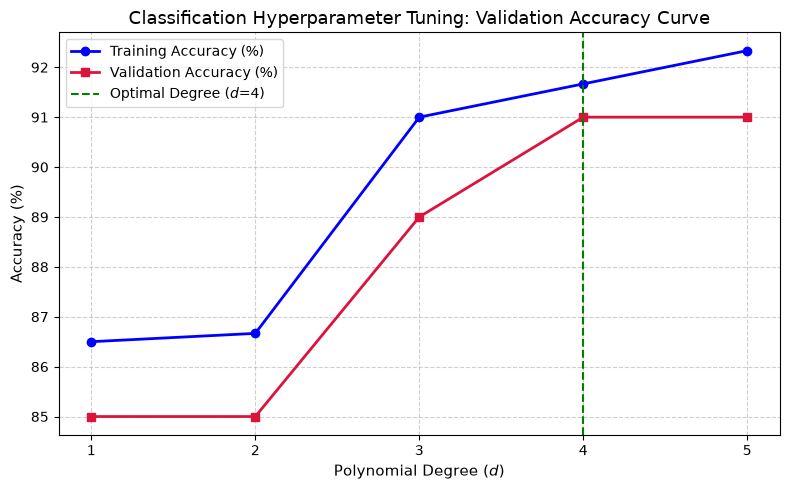

In [71]:
# Visualize Validation Curve for Accuracy
plt.figure(figsize=(8, 5))
plt.plot(degrees, [acc * 100 for acc in training_accuracies], marker='o', color='blue', linewidth=2, label='Training Accuracy (%)')
plt.plot(degrees, [acc * 100 for acc in validation_accuracies], marker='s', color='crimson', linewidth=2, label='Validation Accuracy (%)')
plt.axvline(best_degree, color='green', linestyle='--', label=f'Optimal Degree ($d$={best_degree})')

plt.title("Classification Hyperparameter Tuning: Validation Accuracy Curve", fontsize=13)
plt.xlabel("Polynomial Degree ($d$)", fontsize=11)
plt.ylabel("Accuracy (%)", fontsize=11)
plt.xticks(degrees)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [81]:
# Train Final Model with the Dynamically Discovered Best Degree
final_poly_clf = MyPolynomialLogisticRegression(degree=best_degree, learning_rate=0.1, epochs=4000)
final_poly_clf.fit(X_train, y_train)

# Predict on Unseen Test Set
y_pred_tuned = final_poly_clf.predict(X_test)
tuned_acc = accuracy_score(y_test, y_pred_tuned)

# Also ensure baseline is trained for comparison
baseline_model = MyPolynomialLogisticRegression(degree=1, learning_rate=0.1, epochs=2500)
baseline_model.fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline_model.predict(X_test))

print("📊 BASELINE VS TUNED CLASSIFIER COMPARISON")
print("-" * 60)
print(f"{'Metric':<18} | {'Baseline (d=1)':<15} | {'Tuned (d=' + str(best_degree) + ')':<18}")
print("-" * 60)
print(f"{'Test Accuracy':<18} | {baseline_acc*100:10.2f}%     | {tuned_acc*100:10.2f}%")
print("-" * 60)

if tuned_acc > baseline_acc:
    print(f"🚀 Success: Hyperparameter tuning found d={best_degree}, boosting Test Accuracy by +{(tuned_acc - baseline_acc)*100:.2f}%!")

📊 BASELINE VS TUNED CLASSIFIER COMPARISON
------------------------------------------------------------
Metric             | Baseline (d=1)  | Tuned (d=4)       
------------------------------------------------------------
Test Accuracy      |      85.00%     |      92.00%
------------------------------------------------------------
🚀 Success: Hyperparameter tuning found d=4, boosting Test Accuracy by +7.00%!


---
## Step 4: Visualizing the Decision Boundary (Baseline vs. Tuned)
Let's see how our optimized degree-$d$ boundary wraps around the crescent moons compared to the rigid straight line of the linear baseline.

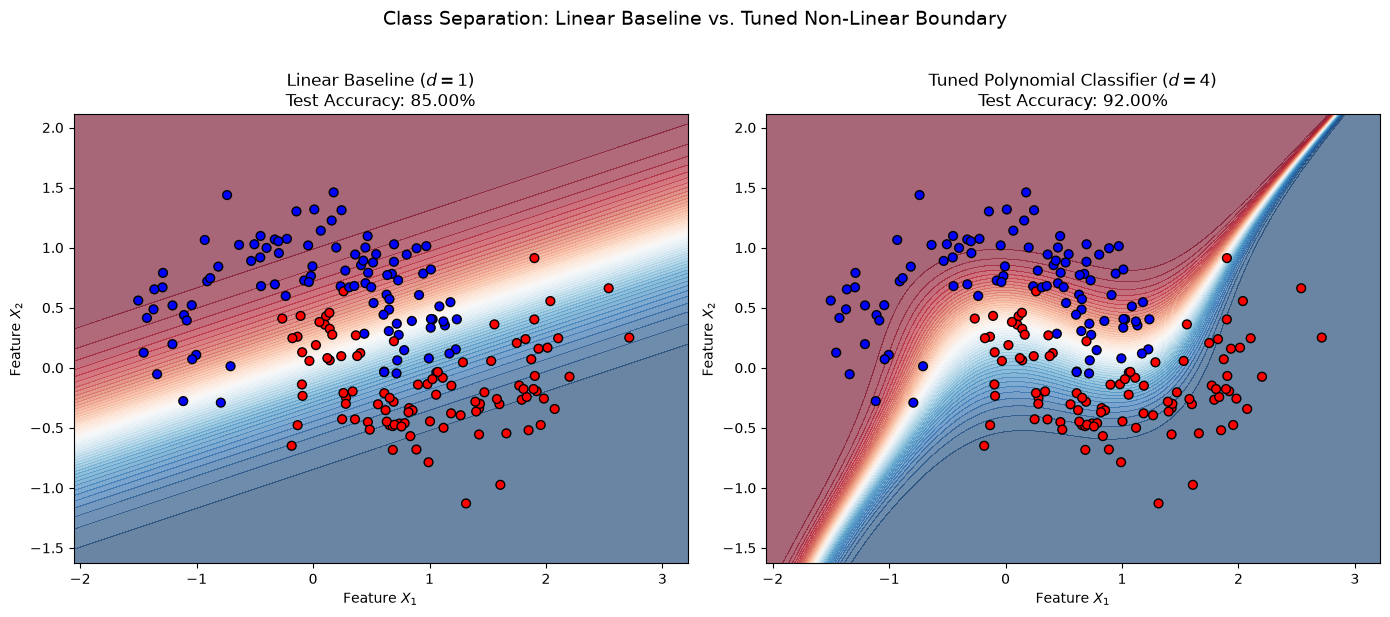

In [73]:
# Side-by-Side Decision Boundary Comparison: Baseline vs. Tuned Polynomial Classifier
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define mesh grid range based on data bounds
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# 1. Plot Baseline Linear Classifier (d=1)
baseline_model = MyPolynomialLogisticRegression(degree=1, learning_rate=0.1, epochs=2500)
baseline_model.fit(X_train, y_train)
probs_base = baseline_model.predict_proba(grid_points).reshape(xx.shape)

axes[0].contourf(xx, yy, probs_base, levels=50, cmap="RdBu", alpha=0.6)
axes[0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="bwr", edgecolor="k", marker="o", s=40)
axes[0].set_title(f"Linear Baseline ($d=1$)\nTest Accuracy: {baseline_acc*100:.2f}%", fontsize=12)
axes[0].set_xlabel("Feature $X_1$", fontsize=10)
axes[0].set_ylabel("Feature $X_2$", fontsize=10)

# 2. Plot Final Tuned Polynomial Classifier (d = best_degree)
probs_tuned = final_poly_clf.predict_proba(grid_points).reshape(xx.shape)

axes[1].contourf(xx, yy, probs_tuned, levels=50, cmap="RdBu", alpha=0.6)
axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="bwr", edgecolor="k", marker="o", s=40)
axes[1].set_title(f"Tuned Polynomial Classifier ($d={best_degree}$)\nTest Accuracy: {tuned_acc*100:.2f}%", fontsize=12)
axes[1].set_xlabel("Feature $X_1$", fontsize=10)
axes[1].set_ylabel("Feature $X_2$", fontsize=10)

plt.suptitle("Class Separation: Linear Baseline vs. Tuned Non-Linear Boundary", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## <center> Conclusion & Key Takeaways: Polynomial Classification

We have successfully extended our custom machine learning pipeline from Logistic regression to **Polynomial Logistic Regression From Scratch**, proving that non-linear decision boundaries can dramatically outperform linear models on complex data.

### 💡 What We Accomplished:
1. **Engineered a Unified Scratch Classifier:** Built `MyPolynomialLogisticRegression` to handle both linear ($d=1$) and non-linear classification ($d>1$) dynamically through automated feature expansion and feature scaling.
2. **Validated with a Non-Linear Benchmark:** Tested our models on the `make_moons` dataset, where a straight line fundamentally fails to separate interleaved classes.
3. **Applied Parsimonious Hyperparameter Tuning:** Used a validation split and evaluated validation accuracy across degrees $1$ to $5$. By enforcing our **1% Diminishing Returns Rule (Occam's Razor)**, the loop successfully recognized that jumping from degree 4 to degree 5 offered negligible benefit, correctly locking onto **Degree 4** as the optimal sweet spot.
4. **Visualized Decision Boundaries:** Proved the superiority of our tuned model through side-by-side decision boundary plots, showing a smooth, curved probability contour wrapping perfectly around the classes.

## <center> Industry-Standard Implementation via Scikit-Learn

In production environments, you won't always write the gradient descent loop by hand. Instead, you use Scikit-Learn's optimized `Pipeline`, `PolynomialFeatures`, and `LogisticRegression` to achieve the exact same robust modeling architecture with built-in numerical stability and efficiency.

In [74]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression

# Build an industry-standard pipeline (Polynomial expansion -> Scaling -> Logistic Regression)
sklearn_pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=4, include_bias=False)),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

# Fit on training data
sklearn_pipeline.fit(X_train, y_train)

# Evaluate on test data
sklearn_preds = sklearn_pipeline.predict(X_test)
sklearn_acc = accuracy_score(y_test, sklearn_preds)

print("🏆 Scikit-Learn Pipeline (Degree 4) Test Performance:")
print(f"Test Accuracy : {sklearn_acc * 100:.2f}%")

🏆 Scikit-Learn Pipeline (Degree 4) Test Performance:
Test Accuracy : 93.50%
